Loaded successfully: (25000,) (25000,)
Vocabulary Size: 88584
Epoch 1/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 60s 141ms/step - accuracy: 0.8062 - loss: 0.4180 - val_accuracy: 0.8558 - val_loss: 0.3361
Epoch 2/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 55s 141ms/step - accuracy: 0.9268 - loss: 0.1969 - val_accuracy: 0.8609 - val_loss: 0.3327
Epoch 3/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 55s 140ms/step - accuracy: 0.9654 - loss: 0.1036 - val_accuracy: 0.8574 - val_loss: 0.4407
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.8574 - loss: 0.4407
Test Accuracy: 0.8573600053787231


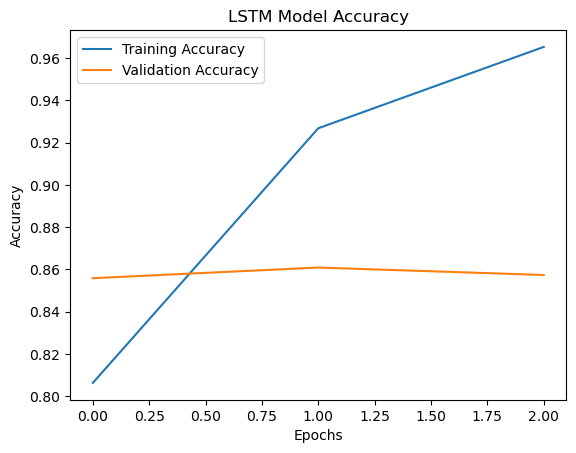

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step
Predicted: Positive
Actual: Positive

Predicted: Positive
Actual: Positive

Predicted: Positive
Actual: Positive

Predicted: Positive
Actual: Positive

Predicted: Positive
Actual: Positive



In [1]:

# Step 1: Import Libraries
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Step 2: Load IMDB Dataset
with np.load("imdb.npz", allow_pickle=True) as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]

print("Loaded successfully:", x_train.shape, y_train.shape)

# Step 3: Preprocessing (Padding)
x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)

# Step 4: Calculate Vocabulary Size Automatically
vocab_size = max(np.max(x_train), np.max(x_test)) + 1
print("Vocabulary Size:", vocab_size)

# Step 5: Build LSTM Model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size, 32),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Step 6: Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Step 7: Train Model
history = model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=64,
    validation_data=(x_test, y_test)
)

# Step 8: Evaluate Model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)

# Step 9: Plot Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('LSTM Model Accuracy')
plt.legend()
plt.show()

# Step 10: Visualize Example Predictions
predictions = model.predict(x_test[:5])

for i in range(5):
    if predictions[i][0] >= 0.5:
        print("Predicted: Positive")
    else:
        print("Predicted: Negative")

    print("Actual:", "Positive" if y_test[i] == 1 else "Negative")
    print()
